## Part A: Optical sensor heart rate
The CSV has two columns: time (s) and the light intensity reflected from a finger.
Each heartbeat changes blood volume, which changes the reflected light (PPG).


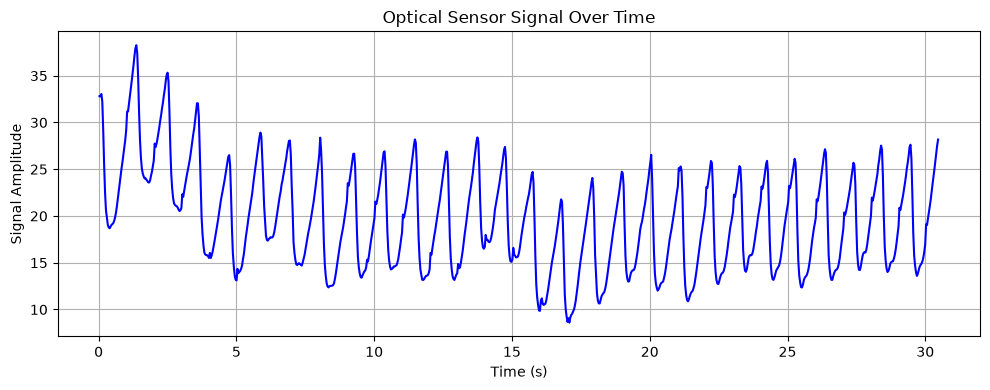

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the optical sensor data
data = pd.read_csv("data/heart_beat_signal.csv",
                   header=None, names=["Time", "Amplitude"])

# Extract time and signal amplitude
time = data["Time"].to_numpy()
signal = data["Amplitude"].to_numpy()

# Plot the original signal
plt.figure(figsize=(10, 4))
plt.plot(time, signal, color="blue")
plt.xlabel("Time (s)")
plt.ylabel("Signal Amplitude")
plt.title("Optical Sensor Signal Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()

## 1.2 Heart rate calculation


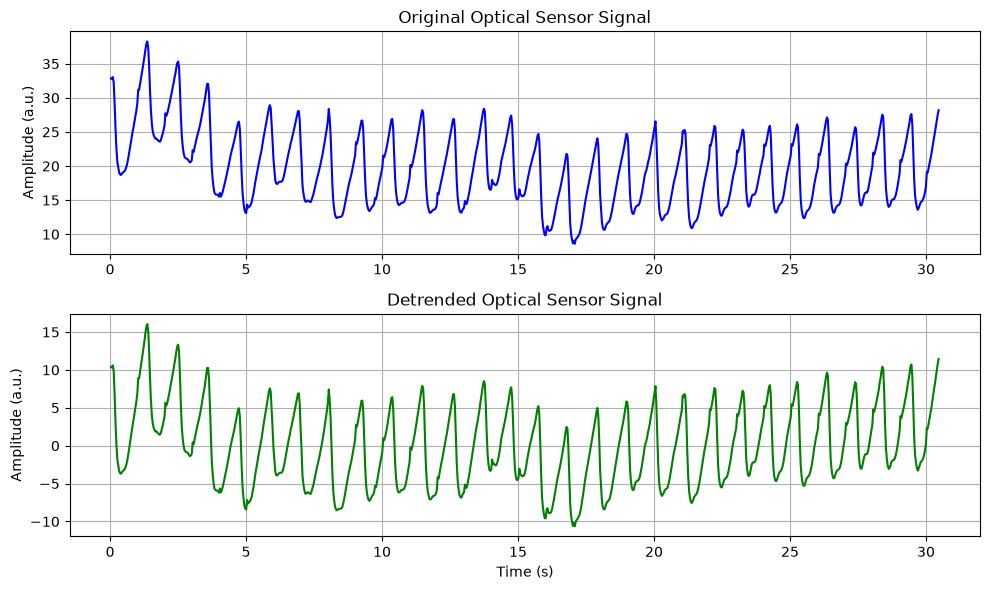

In [2]:
from scipy.signal import detrend

# Remove the mean and linear trend from the signal
detrended_signal = detrend(signal)

# Plot the original and detrended signals
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(time, signal, color="blue")
plt.title("Original Optical Sensor Signal")
plt.ylabel("Amplitude (a.u.)")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, detrended_signal, color="green")
plt.title("Detrended Optical Sensor Signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.grid(True)

plt.tight_layout()
plt.show()


Step 2: Remove baseline drift

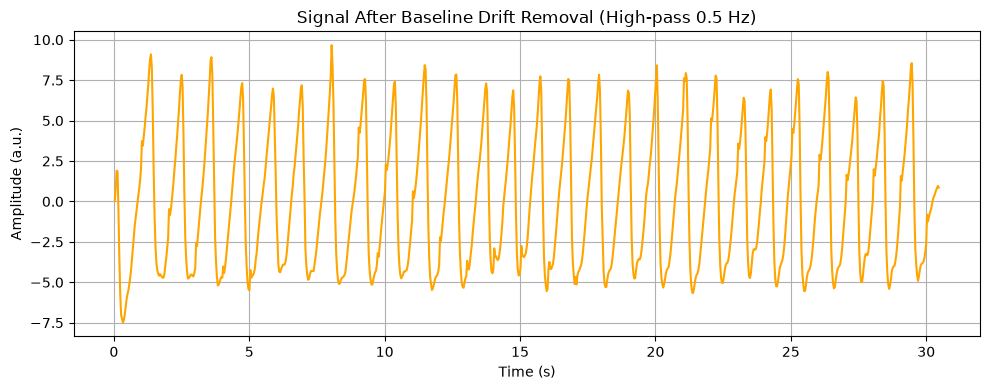

In [3]:
from scipy.signal import butter, filtfilt

# Sampling frequency (Hz)
fs = 1 / np.mean(np.diff(time))

# High-pass filter at 0.5 Hz to remove slow baseline drift
b, a = butter(2, 0.5, btype="highpass", fs=fs)
filtered_signal = filtfilt(b, a, detrended_signal)

plt.figure(figsize=(10, 4))
plt.plot(time, filtered_signal, color="orange")
plt.title("Signal After Baseline Drift Removal (High-pass 0.5 Hz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.grid(True)
plt.tight_layout()
plt.show()

Heart rate using FFT

Sampling frequency: 30.0 Hz
Dominant frequency: 0.92 Hz
Heart rate: 55.1 bpm


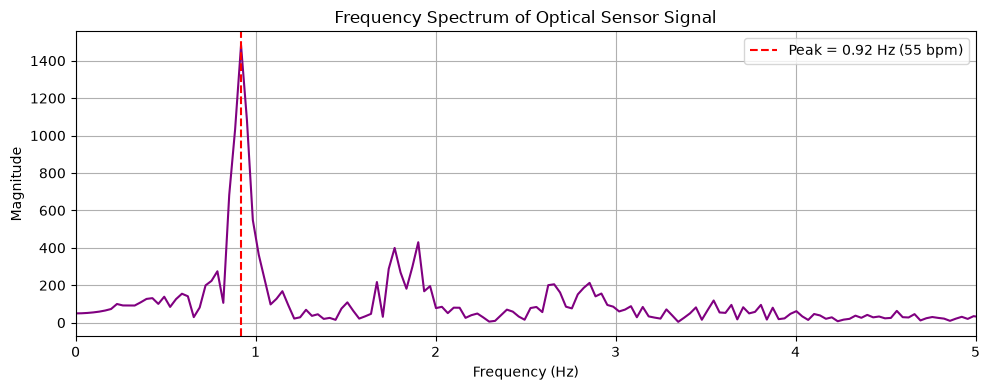

In [4]:
# FFT of the filtered signal
fft_values = np.abs(np.fft.rfft(filtered_signal))
freqs = np.fft.rfftfreq(len(filtered_signal), d=1/fs)

# Only look at realistic heart rates: 0.7–3.5 Hz (42–210 bpm)
mask = (freqs >= 0.7) & (freqs <= 3.5)
peak_freq = freqs[mask][np.argmax(fft_values[mask])]

heart_rate = peak_freq * 60
print(f"Sampling frequency: {fs:.1f} Hz")
print(f"Dominant frequency: {peak_freq:.2f} Hz")
print(f"Heart rate: {heart_rate:.1f} bpm")

# Plot the frequency spectrum
plt.figure(figsize=(10, 4))
plt.plot(freqs, fft_values, color="purple")
plt.axvline(peak_freq, color="red", linestyle="--",
            label=f"Peak = {peak_freq:.2f} Hz ({heart_rate:.0f} bpm)")
plt.xlim(0, 5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum of Optical Sensor Signal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Results: The FFT shows a clear peak at 0.92 Hz, giving a heart rate of 55 bpm. 

The smaller peat at about 1.8 Hz is a harmonic (2 x 0.92 Hz), caused by the pulse shape not being a perfect sine wave, so it is not a second heart rate. As a check, counting the peaks in the time plot gives about 27 beats in 30 seconds. This gives around 54 bpm, which agrees.

Limitations: With 30 s of data, the frequency resolution is 1/30 = 0.033 Hz, so the result is accurate to about ±2 bpm.